# Lab 5: Vacuum Robot with Q-Learning

A vacuum robot learns to reach the +10 cell of a 4x4 grid. It does not know the
transition model T or the reward function R, so instead of value iteration
(AIMA ch. 17) it learns Q-values from experience with Q-learning (AIMA ch. 22).

```text
         col 0   col 1   col 2   col 3
row 0    START     r       r       r
row 1      r       X       r       r
row 2      r       r       r       r
row 3      r      -1       r      +10
```

- `X` is a wall; `-1` and `+10` are terminal; every other cell gives the living reward `r`.
- Moves are slippery: 80% as intended, 10% to each side. Bumping into the wall or edge stays put.

## Chosen hyperparameters

In [1]:
import random
import statistics

import matplotlib.pyplot as plt

from aima.mdp import best_policy, value_iteration
from experiments.sweep import evaluate
from vacuum.environment import COLS, ROWS, WALL, make_vacuum_mdp, policy_grid, to_xy
from vacuum.learning import train

LIVING_REWARD = -0.04
GAMMA = 0.9
ALPHA = 0.3
EPSILON = 0.1
EPISODES = 2000
SEED = 0

| Value | Choice | Why |
| --- | --- | --- |
| Living reward | -0.04 | Optimal policy is the same from -0.04 to -1; a bigger penalty only lowers rewards |
| Discount (gamma) | 0.9 | Fewest steps to the goal (7.7); 0.5 is too short-sighted (9.0), 0.99 learns slower (8.6) |
| Learning rate (alpha) | 0.3 | Reaches +10 in 99.6% of runs in 7.8 steps (optimal 7.4); 0.1 is slower, 0.5+ is noisy |
| Epsilon | 0.1 | 0 locks onto a longer route; 0.2+ wastes reward exploring |

Values come from `experiments/sweep.py`: one value varied at a time, 20 seeds each, 500 episodes.

## Train the agent

In [2]:
mdp = make_vacuum_mdp(LIVING_REWARD, GAMMA)
agent, rewards = train(mdp, EPISODES, alpha=ALPHA, epsilon=EPSILON, seed=SEED)
print(f"First 100 episodes: mean reward {statistics.mean(rewards[:100]):.2f}")
print(f"Last 100 episodes:  mean reward {statistics.mean(rewards[-100:]):.2f}")

First 100 episodes: mean reward 8.88
Last 100 episodes:  mean reward 9.52


## Reward per episode

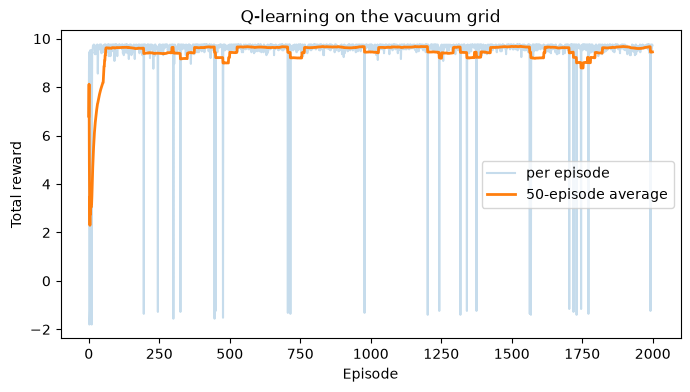

In [3]:
window = 50
smoothed = [statistics.mean(rewards[max(0, i - window + 1):i + 1]) for i in range(len(rewards))]
plt.figure(figsize=(8, 4))
plt.plot(rewards, alpha=0.25, label="per episode")
plt.plot(smoothed, linewidth=2, label=f"{window}-episode average")
plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.title("Q-learning on the vacuum grid")
plt.legend()
plt.show()

## Learned policy vs. the optimal policy

Value iteration needs T and R, which the agent never sees; it is used here only to check the result.

In [4]:
learned = agent.greedy_policy(mdp)
optimal = best_policy(mdp, value_iteration(mdp))
print("Learned (Q-learning):")
print(policy_grid(mdp, learned))
print("\nOptimal (value iteration):")
print(policy_grid(mdp, optimal))
matches = sum(learned[s] == optimal[s] for s in learned)
print(f"\nSame action in {matches} of {len(learned)} states")

Learned (Q-learning):
  >   >   v   v
  ^   X   v   v
  >   >   v   v
  ^  -1   > +10

Optimal (value iteration):
  >   >   v   v
  v   X   v   v
  >   >   >   v
  ^  -1   > +10

Same action in 11 of 13 states


## Learned Q-values

The highest Q-value in each cell, i.e. the learned utility of that state.

In [5]:
for row in range(ROWS):
    cells = []
    for col in range(COLS):
        state = to_xy((row, col))
        if (row, col) == WALL:
            cells.append("X")
        elif state in mdp.terminals:
            cells.append(f"{mdp.R(state):+g}")
        else:
            cells.append(f"{max(agent.Q[state, a] for a in agent.all_act):.2f}")
    print(" ".join(f"{c:>6}" for c in cells))

  4.80   5.30   5.94   6.40
  3.48      X   6.70   7.81
  4.60   6.52   7.65   8.88
  1.35     -1   8.72    +10


## How well does the learned policy do?

Follow the learned policy greedily for 1000 runs from the start.

In [6]:
random.seed(SEED)
goal_rate, steps = evaluate(mdp, learned, runs=1000)
random.seed(SEED)
opt_rate, opt_steps = evaluate(mdp, optimal, runs=1000)
print(f"Learned: reaches +10 in {goal_rate:.1%} of runs, {steps:.1f} steps on average")
print(f"Optimal: reaches +10 in {opt_rate:.1%} of runs, {opt_steps:.1f} steps on average")

Learned: reaches +10 in 98.2% of runs, 7.8 steps on average
Optimal: reaches +10 in 98.8% of runs, 7.5 steps on average
